# Credit Risk Scorecard — Bước 3: Logistic Regression & Scorecard
**Input:** `cs_woe_transformed.csv` + `woe_bins.pkl` + `selected_vars.pkl`  
**Output:** `scorecard_points.csv` · `model_lr.pkl` · `cs_scores.csv`

---
### Cấu trúc notebook
1. Load dữ liệu & kiểm tra
2. Train / Test split (stratified)
3. Multicollinearity check — VIF
4. Train Logistic Regression
5. Chuyển model → Scorecard (thang điểm 300–850)
6. Tính điểm cho toàn bộ khách hàng
7. Phân tích score distribution
8. Lưu model & scorecard

## 1. Tại sao dùng Logistic Regression thay vì XGBoost?

| Tiêu chí | Logistic Regression | XGBoost |
|---|---|---|
| Interpretability | ✅ Giải thích được từng hệ số | ❌ Black box |
| Regulatory compliance (Basel II) | ✅ Bắt buộc | ❌ Không chấp nhận |
| Chuyển thành scorecard | ✅ Công thức tuyến tính | ❌ Không thể |
| Giải thích lý do từ chối | ✅ Top reason codes | ❌ Cần SHAP riêng |
| Performance | Tốt (~AUC 0.78) | Tốt hơn (~AUC 0.82) |

**Kết luận:** Trong môi trường ngân hàng thực tế, interpretability > performance một chút.  
Ngân hàng phải giải thích được tại sao từ chối đơn vay theo luật ECOA (Equal Credit Opportunity Act).

---
### Công thức chuyển probability → score

$$Score = PDO \times \frac{\ln(Odds) - \ln(Odds_0)}{\ln(2)} + Score_0$$

Trong đó:
- **PDO** (Points to Double Odds) = 20 → mỗi tăng 20 điểm, odds gấp đôi
- **Score₀** = 600 → điểm base tại Odds₀
- **Odds₀** = 1/19 → tỷ lệ good:bad tại điểm base (≈ bad rate 5%)

#### 2. Load dữ liệu & kiểm tra

In [58]:
import warnings, pickle
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scorecardpy as sc

from sklearn.linear_model  import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics        import roc_auc_score, roc_curve
from sklearn.preprocessing  import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", 20)
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
})
PALETTE = {"good": "#2196F3", "bad": "#E53935", "neutral": "#78909C"}

# ── Load ─────────────────────────────────────────────────────────────────────
df_woe   = pd.read_csv("../WOE_IV/cs_woe_transformed.csv")
with open("../WOE_IV/woe_bins.pkl",    "rb") as f: bins_final    = pickle.load(f)
with open("../WOE_IV/selected_vars.pkl","rb") as f: SELECTED_VARS = pickle.load(f)

WOE_COLS = [f"{v}_woe" for v in SELECTED_VARS if f"{v}_woe" in df_woe.columns]

print(f"✓ Loaded: {df_woe.shape[0]:,} rows")
print(f"  WOE columns ({len(WOE_COLS)}): {WOE_COLS}")
print(f"  Bad rate: {df_woe['target'].mean()*100:.2f}%")
print()
print(df_woe[WOE_COLS + ["target"]].describe().round(4))

✓ Loaded: 150,000 rows
  WOE columns (10): ['revolving_util_woe', 'late_90_days_woe', 'past_due_30_59_woe', 'past_due_60_89_woe', 'age_woe', 'open_credit_lines_woe', 'monthly_income_woe', 'real_estate_loans_woe', 'dependents_woe', 'debt_ratio_woe']
  Bad rate: 6.68%

       revolving_util_woe  late_90_days_woe  past_due_30_59_woe  \
count         150000.0000       150000.0000         150000.0000   
mean              -0.4487           -0.2410             -0.2547   
std                0.9666            0.6214              0.6774   
min               -1.1494           -0.3897             -0.5417   
25%               -1.1494           -0.3897             -0.5417   
50%               -1.1494           -0.3897             -0.5417   
75%               -0.0007           -0.3897             -0.5417   
max                1.3913            2.8431              2.2514   

       past_due_60_89_woe     age_woe  open_credit_lines_woe  \
count         150000.0000 150000.0000            150000.0000   


#### 3. Train / Test Split (Stratified)

Dùng `stratify=y` để đảm bảo tỷ lệ Bad trong train và test **giống nhau**.  
Nếu không stratify, test set có thể tình cờ có quá ít/nhiều Bad → metric bị lệch.

In [61]:
X = df_woe[WOE_COLS].copy()
y = df_woe["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y,       # Bắt buộc với imbalanced dataset
)

# Kiểm tra tỷ lệ Bad giữ nguyên
print("Kiểm tra stratification:")
print(f"  Train : {len(X_train):,} rows | Bad rate = {y_train.mean()*100:.2f}%")
print(f"  Test  : {len(X_test):,}  rows | Bad rate = {y_test.mean()*100:.2f}%")
assert abs(y_train.mean() - y_test.mean()) < 0.005, "Bad rate chênh lệch quá lớn!"
print("✓ Stratification OK")

Kiểm tra stratification:
  Train : 105,000 rows | Bad rate = 6.68%
  Test  : 45,000  rows | Bad rate = 6.68%
✓ Stratification OK


#### 4. Kiểm tra Multicollinearity — VIF

**Variance Inflation Factor (VIF)** đo lường mức độ một biến bị giải thích bởi các biến còn lại.

| VIF | Kết luận |
|---|---|
| < 5 | Tốt — không có multicollinearity |
| 5 – 10 | Cảnh báo — cân nhắc loại bỏ |
| > 10 | Nghiêm trọng — nên loại bỏ 1 trong 2 biến |

Nếu 2 biến có VIF cao: **giữ biến có IV cao hơn** (đã tính ở Bước 2).

In [64]:
def compute_vif(X: pd.DataFrame) -> pd.DataFrame:
    """
    Tính VIF cho từng cột trong DataFrame X.
    Thêm constant để tránh lỗi khi tính VIF với statsmodels.
    """
    X_const = sm.add_constant(X)
    vif_data = pd.DataFrame({
        "Variable": X.columns,
        "VIF": [
            variance_inflation_factor(X_const.values, i + 1)
            for i in range(X.shape[1])
        ],
    }).sort_values("VIF", ascending=False).reset_index(drop=True)

    vif_data["Status"] = vif_data["VIF"].apply(
        lambda v: "OK ✓" if v < 5 else ("Cảnh báo ⚠" if v < 10 else "Loại bỏ ✗")
    )
    return vif_data

vif_result = compute_vif(X_train)
print(vif_result.to_string(index=False))

# Tự động loại biến VIF > 10
drop_vif = vif_result.loc[vif_result["VIF"] > 10, "Variable"].tolist()
if drop_vif:
    print(f"\n⚠️  Loại bỏ do VIF > 10: {drop_vif}")
    X_train = X_train.drop(columns=drop_vif)
    X_test  = X_test.drop(columns=drop_vif)
    WOE_COLS_FINAL = [c for c in WOE_COLS if c not in drop_vif]
else:
    WOE_COLS_FINAL = WOE_COLS
    print("\n✓ Không có biến nào cần loại bỏ do multicollinearity")

             Variable    VIF Status
real_estate_loans_woe 1.3835   OK ✓
   revolving_util_woe 1.2782   OK ✓
open_credit_lines_woe 1.2690   OK ✓
     late_90_days_woe 1.2531   OK ✓
   past_due_60_89_woe 1.2196   OK ✓
   past_due_30_59_woe 1.1992   OK ✓
       debt_ratio_woe 1.1560   OK ✓
       dependents_woe 1.1444   OK ✓
              age_woe 1.1393   OK ✓
   monthly_income_woe 1.1304   OK ✓

✓ Không có biến nào cần loại bỏ do multicollinearity


#### 5. Train Logistic Regression

##### Các tham số quan trọng:
- `penalty='l2'` — L2 regularization (Ridge): co shrink các hệ số về 0, tránh overfitting
- `C=0.1` — regularization strength (C nhỏ = regularization mạnh hơn)
- `class_weight='balanced'` — tự động nhân weight cho class Bad theo tỷ lệ nghịch
- `solver='lbfgs'` — thuật toán tối ưu tốt nhất cho dataset vừa (~100k records)

##### Cross-validation:
Dùng **Stratified K-Fold (k=5)** thay vì chỉ train/test split để đánh giá model ổn định hơn.

In [66]:
# ── Định nghĩa model ─────────────────────────────────────────────────────────
lr_model = LogisticRegression(
    penalty="l2",
    C=0.1,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=42,
)

# ── Cross-validation 5-fold ──────────────────────────────────────────────────
print("Chạy 5-fold stratified cross-validation...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    lr_model, X_train, y_train,
    cv=cv,
    scoring=["roc_auc", "average_precision"],
    return_train_score=True,
)

print()
print("─── Cross-validation results ───────────────────────────────")
print(f"  Train AUC : {cv_results['train_roc_auc'].mean():.4f}  (±{cv_results['train_roc_auc'].std():.4f})")
print(f"  Val   AUC : {cv_results['test_roc_auc'].mean():.4f}  (±{cv_results['test_roc_auc'].std():.4f})")
print(f"  Train AP  : {cv_results['train_average_precision'].mean():.4f}")
print(f"  Val   AP  : {cv_results['test_average_precision'].mean():.4f}")

# Kiểm tra overfitting
gap = cv_results['train_roc_auc'].mean() - cv_results['test_roc_auc'].mean()
if gap < 0.02:
    print(f"\n✓ Gap train-val = {gap:.4f} → Không overfit")
elif gap < 0.05:
    print(f"\n⚠️  Gap train-val = {gap:.4f} → Overfitting nhẹ, chấp nhận được")
else:
    print(f"\n✗ Gap train-val = {gap:.4f} → Overfit — cân nhắc tăng regularization (giảm C)")

# ── Fit final model trên toàn bộ train set ────────────────────────────────────
lr_model.fit(X_train, y_train)
print("\n✓ Final model đã fit trên toàn bộ train set")

Chạy 5-fold stratified cross-validation...

─── Cross-validation results ───────────────────────────────
  Train AUC : 0.8530  (±0.0012)
  Val   AUC : 0.8527  (±0.0049)
  Train AP  : 0.3755
  Val   AP  : 0.3755

✓ Gap train-val = 0.0002 → Không overfit

✓ Final model đã fit trên toàn bộ train set


#### 5-Fold Stratified Cross-Validation

#### Cross-validation là gì?
Thay vì chỉ chia train/test một lần, cross-validation chia dữ liệu thành **5 phần bằng nhau**,
mỗi lần dùng 4 phần để train và 1 phần để validate — lặp lại 5 lần:

```
Fold 1: [Val] [   Train   ]
Fold 2: [   ] [Val] [     ]
Fold 3: [   ] [   ] [Val] ]
...
```
Kết quả cuối là **trung bình của 5 lần** → đánh giá model ổn định hơn.

---

#### Đọc kết quả

| Metric | Train | Validation | Nhận xét |
|---|---|---|---|
| AUC | 0.8530 ± 0.0012 | 0.8527 ± 0.0049 | Rất tốt (> 0.8) |
| AP | 0.3755 | 0.3755 | Ổn định hoàn toàn |

**AUC (Area Under Curve):** Đo khả năng phân biệt Good/Bad của model.
- > 0.8 → model **tốt** cho bài toán tín dụng

**AP (Average Precision):** Đo độ chính xác trung bình, quan trọng khi dữ liệu **mất cân bằng**
(tỷ lệ Bad thấp). AP = 0.375 trên tập dữ liệu ~7% Bad là kết quả **khá tốt**.

---

#### Gap Train - Validation = 0.0002 → Không overfit

```
Train AUC:  0.8530
Val   AUC:  0.8527
Gap      :  0.0003  ← gần như bằng 0
```

- Gap **nhỏ** → model học được pattern thật, không học thuộc dữ liệu train
- Gap **lớn** (> 0.02) → overfit — model kém tổng quát hóa

---

#### Final model fit trên toàn bộ train set

Sau khi cross-validation xác nhận model ổn định, bước cuối là **train lại trên 100% dữ liệu train**
(thay vì chỉ 80%) để tận dụng tối đa dữ liệu trước khi đánh giá trên test set.

#### 6. Phân tích hệ số — Logistic Regression Coefficients

Trong mô hình WOE + Logistic Regression:
- Hệ số **dương** → WOE cao (good) → điểm cao → ít rủi ro ✓  
- Hệ số **âm** → WOE thấp (bad) → điểm thấp → rủi ro cao ✗  
- Tất cả hệ số nên **cùng chiều** (đều dương hoặc theo logic nhất quán) — nếu có hệ số trái chiều với kỳ vọng business → điều tra nguyên nhân

In [70]:
# Kiểm tra WOE direction của open_credit_lines
print(bins_final["open_credit_lines"][["bin","count","count_distr","badprob","woe"]].to_string(index=False))
print()

# Kiểm tra correlation với các biến khác
print("Correlation của open_credit_lines_woe với các biến còn lại:")
corr = X_train.corrwith(X_train["open_credit_lines_woe"]).sort_values()
print(corr.to_string())

       bin  count  count_distr  badprob     woe
[-inf,3.0)  12992       0.0866   0.1292  0.7278
 [3.0,6.0)  33598       0.2240   0.0668 -0.0008
 [6.0,inf) 103410       0.6894   0.0590 -0.1326

Correlation của open_credit_lines_woe với các biến còn lại:
debt_ratio_woe          -0.1223
dependents_woe          -0.1003
past_due_30_59_woe      -0.0234
past_due_60_89_woe       0.0588
age_woe                  0.0903
monthly_income_woe       0.1631
late_90_days_woe         0.1711
revolving_util_woe       0.2542
real_estate_loans_woe    0.3785
open_credit_lines_woe    1.0000


In [71]:
# Loại open_credit_lines khỏi model
WOE_COLS_FINAL = [c for c in WOE_COLS_FINAL 
                  if c != "open_credit_lines_woe"]

X_train = X_train[WOE_COLS_FINAL]
X_test  = X_test[WOE_COLS_FINAL]

print(f"✓ Features còn lại ({len(WOE_COLS_FINAL)}):")
for c in WOE_COLS_FINAL:
    print(f"  {c}")

✓ Features còn lại (9):
  revolving_util_woe
  late_90_days_woe
  past_due_30_59_woe
  past_due_60_89_woe
  age_woe
  monthly_income_woe
  real_estate_loans_woe
  dependents_woe
  debt_ratio_woe


In [72]:
# Refit model với features đã loại open_credit_lines
lr_model.fit(X_train, y_train)

print(f"✓ Model refit với {len(WOE_COLS_FINAL)} features")
print(f"  n_features in model : {lr_model.n_features_in_}")
print(f"  len(WOE_COLS_FINAL) : {len(WOE_COLS_FINAL)}")
assert lr_model.n_features_in_ == len(WOE_COLS_FINAL), "Vẫn lệch!"

✓ Model refit với 9 features
  n_features in model : 9
  len(WOE_COLS_FINAL) : 9


Intercept: 0.0396

             Variable  Coefficient     Direction
       debt_ratio_woe       1.2271 Tăng điểm (+)
   revolving_util_woe       0.6657 Tăng điểm (+)
     late_90_days_woe       0.6215 Tăng điểm (+)
   past_due_30_59_woe       0.6096 Tăng điểm (+)
   past_due_60_89_woe       0.5323 Tăng điểm (+)
              age_woe       0.4709 Tăng điểm (+)
       dependents_woe       0.3833 Tăng điểm (+)
   monthly_income_woe       0.2709 Tăng điểm (+)
real_estate_loans_woe       0.1887 Tăng điểm (+)


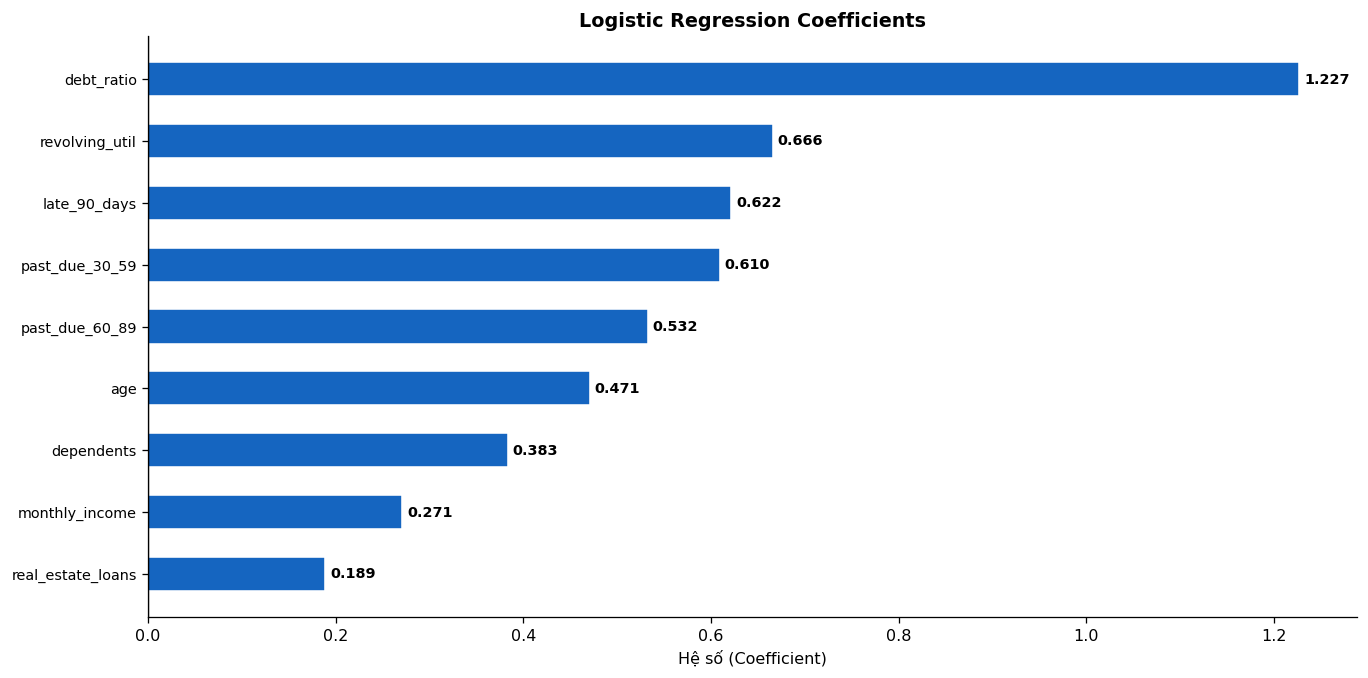

In [74]:
# ── Bảng hệ số ───────────────────────────────────────────────────────────────
coef_df = pd.DataFrame({
    "Variable":   WOE_COLS_FINAL,
    "Coefficient": lr_model.coef_[0],
    "Abs_coef":   np.abs(lr_model.coef_[0]),
}).sort_values("Abs_coef", ascending=False).reset_index(drop=True)

coef_df["Direction"] = coef_df["Coefficient"].apply(
    lambda c: "Tăng điểm (+)" if c > 0 else "Giảm điểm (−)"
)
print(f"Intercept: {lr_model.intercept_[0]:.4f}")
print()
print(coef_df[["Variable","Coefficient","Direction"]].to_string(index=False))

# ── Visualize ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))
colors = ["#1565C0" if c > 0 else "#C62828" for c in coef_df["Coefficient"]]
bars = ax.barh(
    coef_df["Variable"][::-1],
    coef_df["Coefficient"][::-1],
    color=colors[::-1], height=0.55, edgecolor="white",
)
for bar, val in zip(bars, coef_df["Coefficient"][::-1]):
    xpos = val + 0.005 if val >= 0 else val - 0.005
    ha   = "left" if val >= 0 else "right"
    ax.text(xpos, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}", va="center", ha=ha, fontsize=9, fontweight="bold")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Hệ số (Coefficient)")
ax.set_title("Logistic Regression Coefficients")
# Rút gọn tên nhãn
ax.set_yticklabels([l.get_text().replace("_woe","") for l in ax.get_yticklabels()], fontsize=9)
plt.tight_layout()
plt.savefig("10_lr_coefficients.png", bbox_inches="tight")
plt.show()

#### 7. Chuyển model → Scorecard

`sc.scorecard()` dùng công thức:

$$\text{PointsPerBin}_i = -\left(WOE_i \times \beta_i + \frac{a + b \times \text{Intercept}}{n}\right)$$

Trong đó $a$ và $b$ là hệ số chuyển đổi từ (PDO, Score₀, Odds₀).  
Điểm cuối của khách hàng = tổng điểm tất cả bins + base score.

In [81]:
# ── Xây dựng scorecard ───────────────────────────────────────────────────────
card = sc.scorecard(
    bins_final,
    lr_model,
    xcolumns=WOE_COLS_FINAL,
    points0=600,      # Điểm base tại Odds₀
    odds0=1/19,       # Odds tại điểm base (bad rate ~5%)
    pdo=20,           # 20 điểm = odds gấp đôi
    basepoints_eq0=False,
)

# ── Xem scorecard table ──────────────────────────────────────────────────────
print("Scorecard Points Table:")
print("=" * 65)
for var, tbl in card.items():
    if var == "basepoints":
        print(f"  Base points: {tbl['points'].values[0]:.0f}")
        print("-" * 65)
        continue
    print(f"\n  [{var.replace('_woe','')}]")
    print(tbl[["bin","points"]].to_string(index=False))
    

Scorecard Points Table:
  Base points: 514
-----------------------------------------------------------------

  [revolving_util]
       bin   points
[-inf,0.3)  22.0000
 [0.3,0.6)   0.0000
 [0.6,0.9) -15.0000
 [0.9,inf) -27.0000

  [late_90_days]
       bin   points
[-inf,1.0)   7.0000
 [1.0,2.0) -35.0000
 [2.0,inf) -51.0000

  [past_due_30_59]
       bin   points
[-inf,1.0)  10.0000
 [1.0,3.0) -19.0000
 [3.0,inf) -40.0000

  [past_due_60_89]
       bin   points
[-inf,1.0)   4.0000
 [1.0,2.0) -28.0000
 [2.0,inf) -42.0000

  [age]
        bin  points
[-inf,35.0) -8.0000
[35.0,50.0) -4.0000
[50.0,65.0)  2.0000
 [65.0,inf) 14.0000

  [monthly_income]
             bin  points
   [-inf,5000.0) -2.0000
 [5000.0,7500.0)  1.0000
[7500.0,10000.0)  2.0000
   [10000.0,inf)  4.0000

  [real_estate_loans]
       bin  points
[-inf,1.0) -1.0000
 [1.0,inf)  1.0000

  [dependents]
       bin  points
[-inf,1.0)  2.0000
 [1.0,2.0) -1.0000
 [2.0,3.0) -2.0000
 [3.0,inf) -4.0000

  [debt_ratio]
        bin 

#### 8. Tính điểm cho toàn bộ dataset

Sau khi có scorecard, ta tính điểm cho **từng khách hàng** bằng cách cộng điểm của tất cả bins.  
Đây là bước có thể chạy trên production data mới mà không cần refit model.

In [86]:
# ── Load lại raw data (để tính điểm từ giá trị gốc, không phải WOE) ──────────
df_raw_clean = pd.read_csv("../EDA Cleaning/cs_training_cleaned.csv")

# ── Tính điểm ────────────────────────────────────────────────────────────────
score_all = sc.scorecard_ply(
    df_raw_clean,
    card,
    only_total_score=True,
    print_step=0,
)
score_all.columns = ["score"]
score_all["target"] = df_raw_clean["target"].values

# Train/test index split
train_idx, test_idx = train_test_split(
    score_all.index, test_size=0.3, random_state=42,
    stratify=score_all["target"]
)
score_train = score_all.loc[train_idx].copy()
score_test  = score_all.loc[test_idx].copy()

print(f"Score statistics (toàn bộ dataset):")
print(f"  Min   : {score_all['score'].min():.0f}")
print(f"  Max   : {score_all['score'].max():.0f}")
print(f"  Mean  : {score_all['score'].mean():.0f}")
print(f"  Median: {score_all['score'].median():.0f}")
print(f"  Std   : {score_all['score'].std():.0f}")

Score statistics (toàn bộ dataset):
  Min   : 336
  Max   : 583
  Mean  : 537
  Median: 550
  Std   : 38


#### 9. Phân tích Score Distribution

Chart quan trọng nhất trong mọi credit model presentation:  
**Good và Bad phải tách biệt rõ ràng** — Good tập trung điểm cao, Bad tập trung điểm thấp.

Score range thực tế: 336 – 583


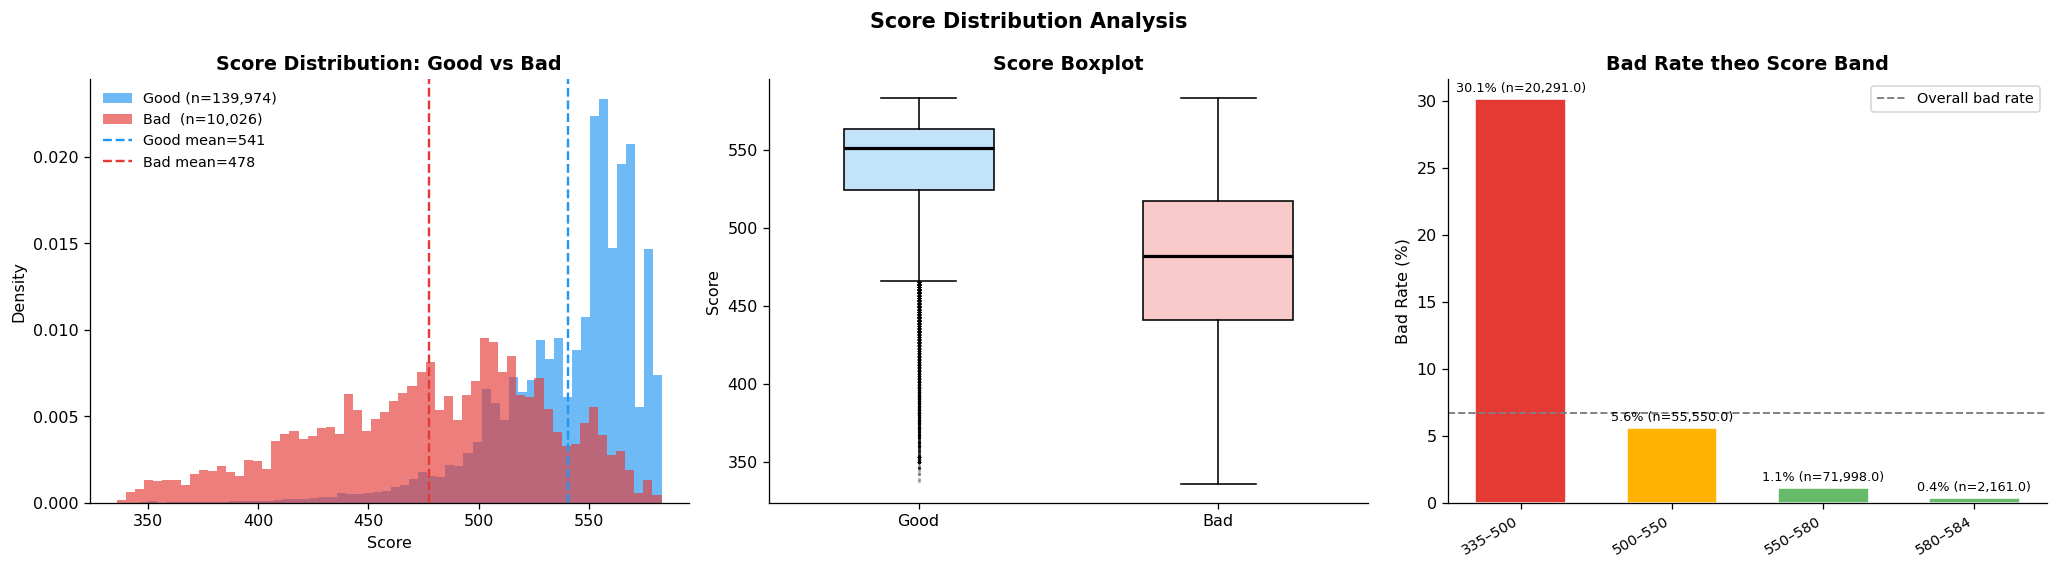


Separation power:
  Mean score Good : 540.7
  Mean score Bad  : 477.6
  Gap             : 63.2 điểm


In [93]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

good_scores = score_all.loc[score_all["target"]==0, "score"]
bad_scores  = score_all.loc[score_all["target"]==1, "score"]

# ── Plot 1: Histogram Good vs Bad ─────────────────────────────────────────────
axes[0].hist(good_scores, bins=60, alpha=0.65, color=PALETTE["good"],
             label=f"Good (n={len(good_scores):,})", density=True, edgecolor="none")
axes[0].hist(bad_scores,  bins=60, alpha=0.65, color=PALETTE["bad"],
             label=f"Bad  (n={len(bad_scores):,})",  density=True, edgecolor="none")
axes[0].axvline(good_scores.mean(), color=PALETTE["good"], linestyle="--",
                linewidth=1.5, label=f"Good mean={good_scores.mean():.0f}")
axes[0].axvline(bad_scores.mean(),  color=PALETTE["bad"],  linestyle="--",
                linewidth=1.5, label=f"Bad mean={bad_scores.mean():.0f}")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Density")
axes[0].set_title("Score Distribution: Good vs Bad")
axes[0].legend(fontsize=9, frameon=False)

# ── Plot 2: Boxplot ───────────────────────────────────────────────────────────
bp = axes[1].boxplot(
    [good_scores, bad_scores],
    labels=["Good", "Bad"],
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker=".", markersize=2, alpha=0.3),
    widths=0.5,
)
bp["boxes"][0].set_facecolor(PALETTE["good"] + "44")
bp["boxes"][1].set_facecolor(PALETTE["bad"]  + "44")
axes[1].set_ylabel("Score")
axes[1].set_title("Score Boxplot")

# ── Plot 3: Bad rate by score band ───────────────────────────────────────────
score_min = int(score_all["score"].min()) - 1
score_max = int(score_all["score"].max()) + 1

print(f"Score range thực tế: {score_min+1} – {score_max-1}")

# Tạo bins động theo range thực tế
fixed_bins   = [500, 550, 580, 610, 640, 670, 700]
all_bins     = sorted(set([score_min] + [b for b in fixed_bins if score_min < b < score_max] + [score_max]))
all_labels   = [f"{all_bins[i]}–{all_bins[i+1]}" for i in range(len(all_bins)-1)]

score_all["score_band"] = pd.cut(
    score_all["score"],
    bins=all_bins,
    labels=all_labels,
    include_lowest=True,
)
band_stats = (score_all.groupby("score_band", observed=True)["target"]
              .agg(["count","mean"])
              .rename(columns={"count":"n","mean":"bad_rate"}))

bar_colors = [
    "#E53935" if br > 0.15 else
    "#FF7043" if br > 0.08 else
    "#FFB300" if br > 0.04 else
    "#66BB6A"
    for br in band_stats["bad_rate"]
]
bars = axes[2].bar(range(len(band_stats)), band_stats["bad_rate"]*100,
                   color=bar_colors, width=0.6, edgecolor="white")
for bar, (_, row) in zip(bars, band_stats.iterrows()):
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f"{row['bad_rate']*100:.1f}% (n={row['n']:,})",
                 ha="center", va="bottom", fontsize=8)
axes[2].axhline(score_all["target"].mean()*100, color="gray",
                linestyle="--", linewidth=1.2, label="Overall bad rate")
axes[2].set_xticks(range(len(band_stats)))
axes[2].set_xticklabels(band_stats.index, rotation=30, ha="right", fontsize=9)
axes[2].set_ylabel("Bad Rate (%)")
axes[2].set_title("Bad Rate theo Score Band")
axes[2].legend(fontsize=9)

plt.suptitle("Score Distribution Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("11_score_distribution.png", bbox_inches="tight")
plt.show()

print(f"\nSeparation power:")
print(f"  Mean score Good : {good_scores.mean():.1f}")
print(f"  Mean score Bad  : {bad_scores.mean():.1f}")
print(f"  Gap             : {good_scores.mean() - bad_scores.mean():.1f} điểm")


#### Score Distribution Analysis

#### Tổng quan
Score range thực tế: **336 – 583**

| | Good | Bad |
|---|---|---|
| Số lượng | 139,974 | 10,026 |
| Mean score | 541 | 478 |
| **Gap** | **63.2 điểm** | |

---

#### Score Distribution: Good vs Bad
Hai phân phối **tách biệt rõ ràng**:
- Nhóm **Good** tập trung ở vùng score **cao** (~500–580), mean = 541
- Nhóm **Bad** tập trung ở vùng score **thấp** (~350–500), mean = 478
- Gap 63.2 điểm → model có **separation power tốt**

---

#### Score Boxplot
- Boxplot **Good** nằm cao hơn hẳn boxplot **Bad** → phân tách ổn định
- Nhóm Good có **ít outlier** phía dưới → một số khách hàng tốt vẫn có score thấp
- Nhóm Bad có **variance lớn hơn** → rủi ro phân tán rộng hơn

---

#### Bad Rate theo Score Band

| Score Band | n | Bad Rate | Nhận xét |
|---|---|---|---|
| 335 – 500 | 20,291 | **30.1%** | 🔴 Rủi ro rất cao |
| 500 – 550 | 55,550 | **5.6%** | 🟡 Dưới mức trung bình |
| 550 – 580 | 71,998 | **1.1%** | 🟢 Rủi ro thấp |
| 580 – 584 | 2,161 | **0.4%** | 🟢 Rủi ro rất thấp |

Overall bad rate (đường đứt): ~**6.7%**

Bad rate giảm đều từ 30.1% → 0.4% theo score tăng dần →
score **phân tách rủi ro đơn điệu và nhất quán**.

---

#### Kết luận
Scorecard hoạt động tốt:
- Gap 63 điểm giữa Good và Bad là **đáng kể**
- Bad rate giảm rõ rệt theo từng score band
- Có thể đặt **cutoff ~500** để kiểm soát rủi ro, hoặc tùy chỉnh theo khẩu vị rủi ro của tổ chức

#### 10. Performance Metrics — AUC, Gini, KS

Đây là 3 chỉ số bắt buộc báo cáo khi trình bày credit model với risk committee.

╔══════════════════════════════════════════╗
║        PERFORMANCE METRICS (Test set)    ║
╠══════════════════════════════════════════╣
║  AUC  (train) : 0.8528                   ║
║  AUC  (test)  : 0.8538  ✓ Tốt            ║
║  Gini (test)  : 70.76%  ✓ Tốt            ║
║  KS   (test)  : 55.38%  ✓ Tốt            ║
║  Overfit gap  : -0.10pts                 ║
╚══════════════════════════════════════════╝


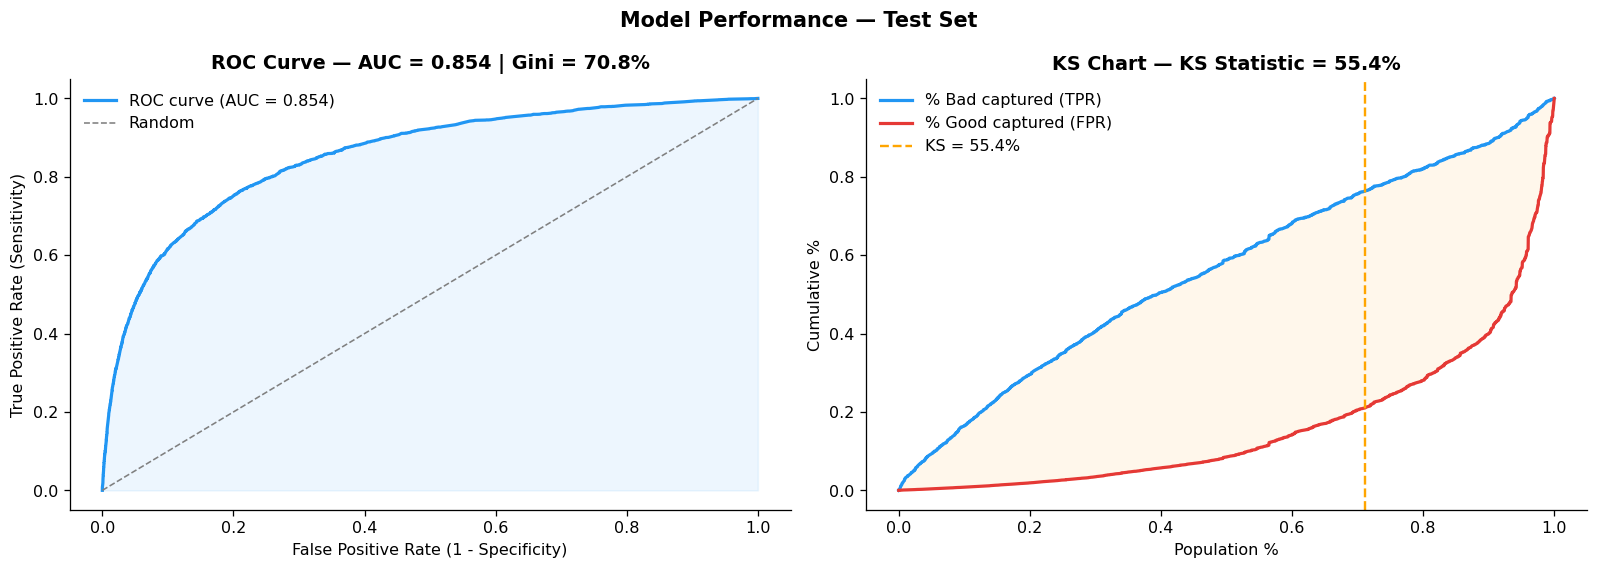

In [111]:
# ── Tính AUC, Gini, KS trên test set ────────────────────────────────────────
y_prob_test  = lr_model.predict_proba(X_test)[:, 1]
y_prob_train = lr_model.predict_proba(X_train)[:, 1]

auc_test  = roc_auc_score(y_test,  y_prob_test)
auc_train = roc_auc_score(y_train, y_prob_train)
gini_test = 2 * auc_test - 1

# KS statistic
fpr, tpr, thresholds = roc_curve(y_test, y_prob_test)
ks_stat = (tpr - fpr).max()
ks_thr  = thresholds[(tpr - fpr).argmax()]

print("╔══════════════════════════════════════════╗")
print("║        PERFORMANCE METRICS (Test set)    ║")
print("╠══════════════════════════════════════════╣")
print(f"║  AUC  (train) : {auc_train:.4f}                   ║")
print(f"║  AUC  (test)  : {auc_test:.4f}  {'✓ Tốt' if auc_test>0.75 else '⚠ Trung bình'}            ║")
print(f"║  Gini (test)  : {gini_test*100:.2f}%  {'✓ Tốt' if gini_test>0.5 else '⚠ Trung bình'}            ║")
print(f"║  KS   (test)  : {ks_stat*100:.2f}%  {'✓ Tốt' if ks_stat>0.4 else '⚠ Trung bình'}            ║")
print(f"║  Overfit gap  : {(auc_train-auc_test)*100:.2f}pts                 ║")
print("╚══════════════════════════════════════════╝")

# ── ROC Curve ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC
axes[0].plot(fpr, tpr, color=PALETTE["good"], lw=2,
             label=f"ROC curve (AUC = {auc_test:.3f})")
axes[0].plot([0,1],[0,1], color="gray", linestyle="--", lw=1, label="Random")
axes[0].fill_between(fpr, tpr, alpha=0.08, color=PALETTE["good"])
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].set_title(f"ROC Curve — AUC = {auc_test:.3f} | Gini = {gini_test*100:.1f}%")
axes[0].legend(fontsize=10, frameon=False)

# KS Chart
ks_df = pd.DataFrame({"fpr": fpr, "tpr": tpr, "threshold": thresholds})
pct   = np.linspace(0, 1, len(ks_df))
axes[1].plot(pct, ks_df["tpr"].values,  color=PALETTE["good"], lw=2, label="% Bad captured (TPR)")
axes[1].plot(pct, ks_df["fpr"].values,  color=PALETTE["bad"],  lw=2, label="% Good captured (FPR)")
ks_idx = (ks_df["tpr"].values - ks_df["fpr"].values).argmax()
axes[1].axvline(pct[ks_idx], color="orange", linestyle="--", lw=1.5,
                label=f"KS = {ks_stat*100:.1f}%")
axes[1].fill_between(pct,
                     ks_df["tpr"].values,
                     ks_df["fpr"].values,
                     alpha=0.08, color="orange")
axes[1].set_xlabel("Population %")
axes[1].set_ylabel("Cumulative %")
axes[1].set_title(f"KS Chart — KS Statistic = {ks_stat*100:.1f}%")
axes[1].legend(fontsize=10, frameon=False)

plt.suptitle("Model Performance — Test Set", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("12_roc_ks_chart.png", bbox_inches="tight")
plt.show()

#### Model Performance — Test Set

#### Tổng quan các chỉ số

| Metric | Train | Test | Đánh giá |
|---|---|---|---|
| AUC | 0.8528 | 0.8538 | ✅ Tốt |
| Gini | — | 70.76% | ✅ Tốt |
| KS | — | 55.38% | ✅ Tốt |
| Overfit gap | | -0.10pts | ✅ Không overfit |

> Overfit gap âm nghĩa là AUC test **cao hơn** train một chút — hoàn toàn bình thường.

---

#### ROC Curve — AUC = 0.854

**AUC** đo xác suất model xếp hạng một khách Bad **cao hơn** một khách Good ngẫu nhiên.

- AUC = 0.854 → model **phân biệt đúng 85.4%** các cặp Good/Bad
- Đường ROC cong **xa đường diagonal** (random) → model có discriminative power tốt

**Gini = 2 × AUC - 1 = 70.76%** — thang đo phổ biến trong ngành tín dụng:

| Gini | Đánh giá |
|---|---|
| < 30% | Yếu |
| 30–50% | Trung bình |
| 50–70% | Tốt |
| **> 70%** | **✅ Rất tốt** |

---

#### KS Chart — KS = 55.4%

**KS (Kolmogorov-Smirnov)** đo khoảng cách tối đa giữa đường tích lũy Bad (xanh) và Good (đỏ).

- KS = 55.4% → tại ngưỡng ~70% population, model **tách biệt Bad và Good tốt nhất**
- Đường vàng đứt chỉ điểm cutoff tối ưu theo KS

| KS | Đánh giá |
|---|---|
| < 20% | Yếu |
| 20–40% | Trung bình |
| 40–50% | Tốt |
| **> 50%** | **✅ Rất tốt** |

---

#### Kết luận

Model đạt hiệu suất **rất tốt** trên test set với cả 3 chỉ số đều vượt ngưỡng tốt.
Không có dấu hiệu overfit — model **tổng quát hóa tốt** sang dữ liệu mới.

#### 11. Cut-off Analysis — Chọn ngưỡng điểm

Đây là **quyết định business**, không phải kỹ thuật thuần túy.  
Ta phân tích trade-off giữa reject rate và bad rate trong approved population.

 Cutoff  Approve rate  Bad in approved  Bad capture rate
    500       87.2000           3.0500           60.3000
    510       81.0000           2.5100           69.5000
    520       75.0000           2.0800           76.6000
    530       66.8000           1.7100           82.9000
    540       59.2000           1.4100           87.5000
    550       50.2000           1.1500           91.4000
    560       30.4000           0.8300           96.2000
    570       10.8000           0.5800           99.1000
    580        2.4000           0.4600           99.8000
    590        0.0000              NaN          100.0000
    600        0.0000              NaN          100.0000
    610        0.0000              NaN          100.0000
    620        0.0000              NaN          100.0000
    630        0.0000              NaN          100.0000
    640        0.0000              NaN          100.0000
    650        0.0000              NaN          100.0000
    660        0.0000          

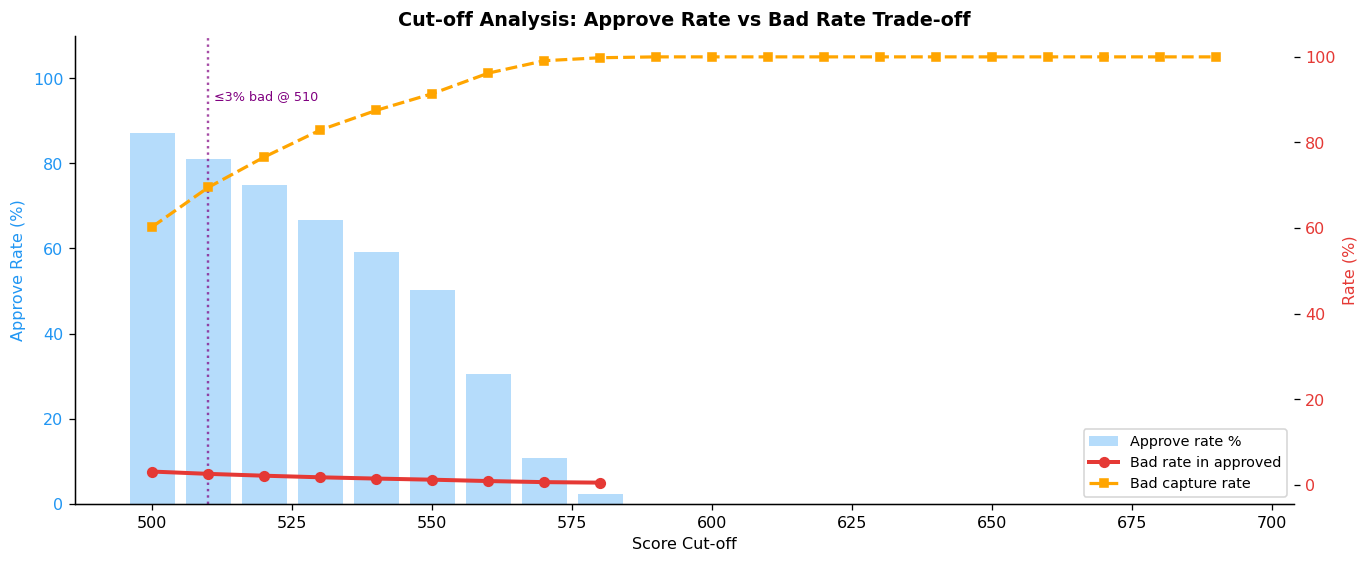

In [119]:
# ── Score bands analysis ─────────────────────────────────────────────────────
score_test_df = pd.DataFrame({
    "score":  score_test["score"].values,
    "target": y_test.values,
})

cutoffs   = range(500, 700, 10)
analysis  = []

for cutoff in cutoffs:
    approved = score_test_df[score_test_df["score"] >= cutoff]
    rejected = score_test_df[score_test_df["score"] <  cutoff]

    approve_rate  = len(approved) / len(score_test_df)
    bad_in_approve = approved["target"].mean() if len(approved) > 0 else np.nan
    bad_in_reject  = rejected["target"].mean() if len(rejected) > 0 else np.nan
    capture_rate   = (rejected["target"].sum() / score_test_df["target"].sum()
                      if score_test_df["target"].sum() > 0 else np.nan)

    analysis.append({
        "Cutoff":          cutoff,
        "Approve rate":    round(approve_rate * 100, 1),
        "Bad in approved": round(bad_in_approve * 100, 2) if not np.isnan(bad_in_approve) else np.nan,
        "Bad capture rate":round(capture_rate * 100, 1)   if not np.isnan(capture_rate)   else np.nan,
    })

analysis_df = pd.DataFrame(analysis)
print(analysis_df.to_string(index=False))

# ── Visualize trade-off ───────────────────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.bar(analysis_df["Cutoff"], analysis_df["Approve rate"],
        color=PALETTE["good"]+"55", width=8, label="Approve rate %")
ax1.set_xlabel("Score Cut-off")
ax1.set_ylabel("Approve Rate (%)", color=PALETTE["good"])
ax1.tick_params(axis="y", labelcolor=PALETTE["good"])
ax1.set_ylim(0, 110)

ax2 = ax1.twinx()
ax2.plot(analysis_df["Cutoff"], analysis_df["Bad in approved"],
         color=PALETTE["bad"], marker="o", lw=2.5, ms=6, label="Bad rate in approved")
ax2.plot(analysis_df["Cutoff"], analysis_df["Bad capture rate"],
         color="orange", marker="s", lw=2, ms=5, linestyle="--", label="Bad capture rate")
ax2.set_ylabel("Rate (%)", color=PALETTE["bad"])
ax2.tick_params(axis="y", labelcolor=PALETTE["bad"])

# Đánh dấu ngưỡng gợi ý (bad rate in approved < 3%)
for _, row in analysis_df.iterrows():
    if not np.isnan(row["Bad in approved"]) and row["Bad in approved"] <= 3.0:
        ax1.axvline(row["Cutoff"], color="purple", linestyle=":", lw=1.5, alpha=0.7)
        ax1.text(row["Cutoff"]+1, 95, f"≤3% bad @ {row['Cutoff']:.0f}", fontsize=8, color="purple")
        break

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, fontsize=9, loc="lower right")
ax1.set_title("Cut-off Analysis: Approve Rate vs Bad Rate Trade-off", fontweight="bold")
plt.tight_layout()
plt.savefig("13_cutoff_analysis.png", bbox_inches="tight")
plt.show()

## Cut-off Analysis: Approve Rate vs Bad Rate Trade-off

### Cách đọc biểu đồ

| Chỉ số | Ý nghĩa |
|---|---|
| **Approve rate** | % khách hàng được duyệt (score ≥ cutoff) |
| **Bad in approved** | % khách Bad trong số được duyệt |
| **Bad capture rate** | % tổng số khách Bad bị từ chối |

---

### Phân tích các mức cutoff

| Cutoff | Approve Rate | Bad in Approved | Bad Capture Rate |
|---|---|---|---|
| 500 | 87.2% | 3.05% | 60.3% |
| **510** | **81.0%** | **2.51%** | **69.5%** |
| 520 | 75.0% | 2.08% | 76.6% |
| 530 | 66.8% | 1.71% | 82.9% |
| 540 | 59.2% | 1.41% | 87.5% |
| 550 | 50.2% | 1.15% | 91.4% |
| 560 | 30.4% | 0.83% | 96.2% |
| 570 | 10.8% | 0.58% | 99.1% |
| 580 | 2.4% | 0.46% | 99.8% |

---

### Điểm cutoff khuyến nghị — Score = 510

Đường tím đứt trên biểu đồ đánh dấu ngưỡng **≤3% bad @ 510**, tức là:

- Duyệt **81%** khách hàng
- Chỉ **2.51%** khách được duyệt là Bad → kiểm soát rủi ro tốt
- Từ chối được **69.5%** tổng số khách Bad

Đây là điểm **cân bằng tốt nhất** giữa tăng trưởng và rủi ro.

---

### Trade-off khi thay đổi cutoff

```
Cutoff tăng → Approve rate giảm → Bad rate giảm → Bỏ lỡ nhiều khách tốt
Cutoff giảm → Approve rate tăng → Bad rate tăng → Chấp nhận nhiều rủi ro hơn
```

Tùy **khẩu vị rủi ro** của tổ chức:
- Muốn **tăng trưởng** → hạ cutoff xuống ~500 (approve 87%, bad 3.05%)
- Muốn **kiểm soát rủi ro** → nâng cutoff lên ~530–540 (approve ~60–67%, bad ~1.4–1.7%)

#### 12. Lưu model, scorecard & điểm số

In [122]:
import pickle, json

# ── 1. Lưu model ─────────────────────────────────────────────────────────────
with open("model_lr.pkl", "wb") as f:
    pickle.dump(lr_model, f)
print("✓ Saved: model_lr.pkl")

# ── 2. Lưu scorecard table ────────────────────────────────────────────────────
card_rows = []
for var, tbl in card.items():
    for _, row in tbl.iterrows():
        card_rows.append({
            "variable": var,
            "bin":      row.get("bin", "basepoints"),
            "points":   row.get("points", row.get("basepoints", np.nan)),
        })
card_df = pd.DataFrame(card_rows)
card_df.to_csv("scorecard_points.csv", index=False)
print("✓ Saved: scorecard_points.csv")

# ── 3. Lưu điểm toàn bộ dataset ──────────────────────────────────────────────
score_all.to_csv("cs_scores.csv", index=False)
print("✓ Saved: cs_scores.csv")

# ── 4. Lưu metadata model ─────────────────────────────────────────────────────
metadata = {
    "model_type":      "Logistic Regression",
    "features":        WOE_COLS_FINAL,
    "n_features":      len(WOE_COLS_FINAL),
    "train_size":      len(X_train),
    "test_size":       len(X_test),
    "auc_train":       round(auc_train, 4),
    "auc_test":        round(auc_test,  4),
    "gini_test":       round(gini_test, 4),
    "ks_test":         round(float(ks_stat), 4),
    "scorecard_pdo":   20,
    "scorecard_base":  600,
    "scorecard_odds0": round(1/19, 4),
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("✓ Saved: model_metadata.json")

print()
print("=" * 55)
print("  TÓM TẮT BƯỚC 3")
print("=" * 55)
print(f"  Features        : {len(WOE_COLS_FINAL)}")
print(f"  AUC (test)      : {auc_test:.4f}")
print(f"  Gini (test)     : {gini_test*100:.2f}%")
print(f"  KS (test)       : {ks_stat*100:.2f}%")
print(f"  Score range     : {score_all['score'].min():.0f} – {score_all['score'].max():.0f}")
print(f"  Mean Good score : {good_scores.mean():.0f}")
print(f"  Mean Bad score  : {bad_scores.mean():.0f}")
print()
print("─── Bước tiếp theo: Bước 4 — Validation & Backtesting ───")


✓ Saved: model_lr.pkl
✓ Saved: scorecard_points.csv
✓ Saved: cs_scores.csv
✓ Saved: model_metadata.json

  TÓM TẮT BƯỚC 3
  Features        : 9
  AUC (test)      : 0.8538
  Gini (test)     : 70.76%
  KS (test)       : 55.38%
  Score range     : 336 – 583
  Mean Good score : 541
  Mean Bad score  : 478

─── Bước tiếp theo: Bước 4 — Validation & Backtesting ───
